# Machine Learning I - Actividad individual - Unidad 2

**Autor:** Jaime Alberto Chica Betancourt  
**Universidad:** Universidad de Investigación y Desarrollo - UDI  
**Programa:** Maestría en Ciencia de Datos e Inteligencia Artificial  
**Asignatura:** 7614 - Machine Learning I  
**Docente:** Jonathan Arley Monsalve Salazar  
**Fecha de entrega:** 25 de octubre de 2026

## Objetivo

Analizar el conjunto de datos *Breast Cancer Wisconsin Dataset* mediante técnicas de clasificación binaria. Se entrenan y comparan los modelos de Regresión Logística y Gaussian Naive Bayes utilizando *accuracy*, matrices de confusión, curvas ROC y AUC.

## 1. Importación de librerías y configuración

Se importan las librerías utilizadas para manipulación de datos, visualización, preparación de variables, entrenamiento y evaluación de los modelos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

# Variable objetivo (la que queremos predecir)
VAL_TARGET = "target"
# Proporción de observaciones utilizadas para prueba
TEST_SIZE = 0.20
# Aleatoriedad para obtener una partición reproducible, de acuerdo a la documentación de scikit-learn
RANDOM_STATE = 42
# Tabla de traducción entre valores numéricos de target y diagnósticos
CLASS_NAMES = ["Maligno", "Benigno"]

## 2. Carga e inspección del conjunto de datos

El conjunto contiene 569 observaciones, 30 variables predictoras numéricas y una variable objetivo denominada `target`. La codificación utilizada es `0 = Maligno` y `1 = Benigno`.

In [2]:
def load_data():
    """
    Carga el dataset como DataFrame e incluye la variable objetivo.
    """
    cancer = load_breast_cancer(as_frame=True)
    df = cancer.frame.copy()
    return df, cancer

def explore_data(df, cancer):
    """
    Muestra estructura, estadísticas y distribución de las clases.
    """
    print("\nDATASET BREAST CANCER WISCONSIN")
    print("=" * 70)
    print(f"Filas: {df.shape[0]}")
    print(f"Columnas: {df.shape[1]}")
    print(f"Variables predictoras: {df.shape[1] - 1}")
    print(f"Clases: {list(cancer.target_names)}")

    print("\nPrimeras cinco filas:")
    print(df.head())

    print("\nInformación general:")
    df.info()

    print("\nEstadísticas descriptivas:")
    print(df.describe().T)

    print("\nValores nulos por variable:")
    print(df.isnull().sum())

    print("\nDistribución de las clases:")
    class_counts = df[VAL_TARGET].value_counts().sort_index()
    for class_value, count in class_counts.items():
        print(f"{class_value} = {CLASS_NAMES[class_value]}: {count}")

In [3]:
df, cancer = load_data()
explore_data(df, cancer)


DATASET BREAST CANCER WISCONSIN
Filas: 569
Columnas: 31
Variables predictoras: 30
Clases: [np.str_('malignant'), np.str_('benign')]

Primeras cinco filas:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           

## 3. Análisis exploratorio de datos

El análisis exploratorio incluye la distribución de las clases, estadísticas descriptivas, histogramas de las variables predictoras y correlaciones con la variable objetivo.

### 3.1. Distribución de las clases

In [4]:
def plot_class_distribution(df):
    """
    Grafica la cantidad de observaciones malignas y benignas.
    """
    counts = df[VAL_TARGET].value_counts().sort_index()

    plt.figure(figsize=(7, 5))
    ax = sns.barplot(x=CLASS_NAMES, y=counts.values, hue=CLASS_NAMES, palette=["#C44E52", "#4C72B0"], legend=False)

    for index, value in enumerate(counts.values):
        ax.text(index, value + 5, str(value), ha="center")

    plt.title("Distribución de las clases")
    plt.xlabel("Diagnóstico")
    plt.ylabel("Número de observaciones")
    plt.tight_layout()
    plt.savefig("class_distribution.png", dpi=300, bbox_inches="tight")

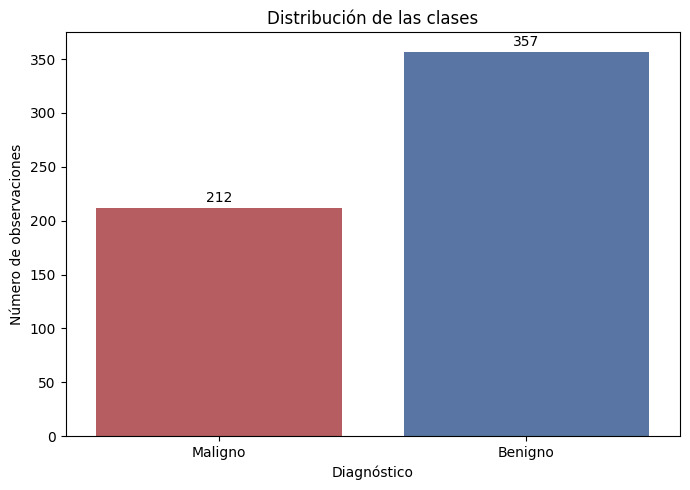

In [5]:
plot_class_distribution(df)

El conjunto de datos contiene 357 casos benignos y 212 malignos. Aunque existe una mayor representación de casos benignos, ambas clases cuentan con un número importante de observaciones. La división posterior de los datos se realiza de forma estratificada para conservar aproximadamente estas proporciones en entrenamiento y prueba.

### 3.2. Estadísticas descriptivas

In [6]:
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean concavity",
    "mean concave points"
]

df[selected_features].describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981,11.70000,13.37000,15.7800,28.1100
mean texture,569.0,19.289649,4.301036,9.710,16.17000,18.84000,21.8000,39.2800
mean perimeter,569.0,91.969033,24.298981,43.790,75.17000,86.24000,104.1000,188.5000
mean area,569.0,654.889104,351.914129,143.500,420.30000,551.10000,782.7000,2501.0000
mean concavity,569.0,0.088799,0.079720,0.000,0.02956,0.06154,0.1307,0.4268
mean concave points,569.0,0.048919,0.038803,0.000,0.02031,0.03350,0.0740,0.2012


Las variables relacionadas con el tamaño del tumor, especialmente `mean area` y `mean perimeter`, presentan una dispersión considerable y valores máximos alejados de sus medianas. `mean concavity` y `mean concave points` muestran valores mínimos de cero y medias superiores a sus medianas, lo que sugiere asimetría hacia valores altos.

### 3.3. Relaciones con la variable objetivo

In [7]:
def plot_correlation_matrix(df):
    """
    Visualiza las correlaciones entre predictores y con la variable objetivo.
    """
    correlation = df.corr()

    # La matriz completa permite observar grupos de variables relacionadas.
    plt.figure(figsize=(18, 15))
    sns.heatmap(correlation, cmap="coolwarm", center=0, square=False, cbar_kws={"shrink": 0.8})
    plt.title("Matriz de correlación - Breast Cancer Wisconsin", fontsize=16)
    plt.tight_layout()
    plt.savefig("correlation_matrix_rocinante.png", dpi=300, bbox_inches="tight")

    # Ordena las correlaciones con target para identificar las más relevantes.
    target_correlation = (correlation[VAL_TARGET]
        .drop(VAL_TARGET)
        .sort_values(key=np.abs, ascending=False)
    )

    print("\nVariables con mayor correlación absoluta respecto a target:")
    print(target_correlation.head(10))

    plt.figure(figsize=(10, 7))
    top_correlations = target_correlation.head(15).sort_values()
    colors = ["#C44E52" if value < 0 else "#4C72B0" for value in top_correlations]
    top_correlations.plot(kind="barh", color=colors)
    plt.title("Variables con mayor correlación respecto a target")
    plt.xlabel("Coeficiente de correlación")
    plt.ylabel("Variable")
    plt.axvline(0, color="black", linewidth=0.8)
    plt.tight_layout()
    plt.savefig("target_correlations.png", dpi=300, bbox_inches="tight")

    return target_correlation


Variables con mayor correlación absoluta respecto a target:
worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
worst area             -0.733825
mean radius            -0.730029
mean area              -0.708984
mean concavity         -0.696360
worst concavity        -0.659610
Name: target, dtype: float64


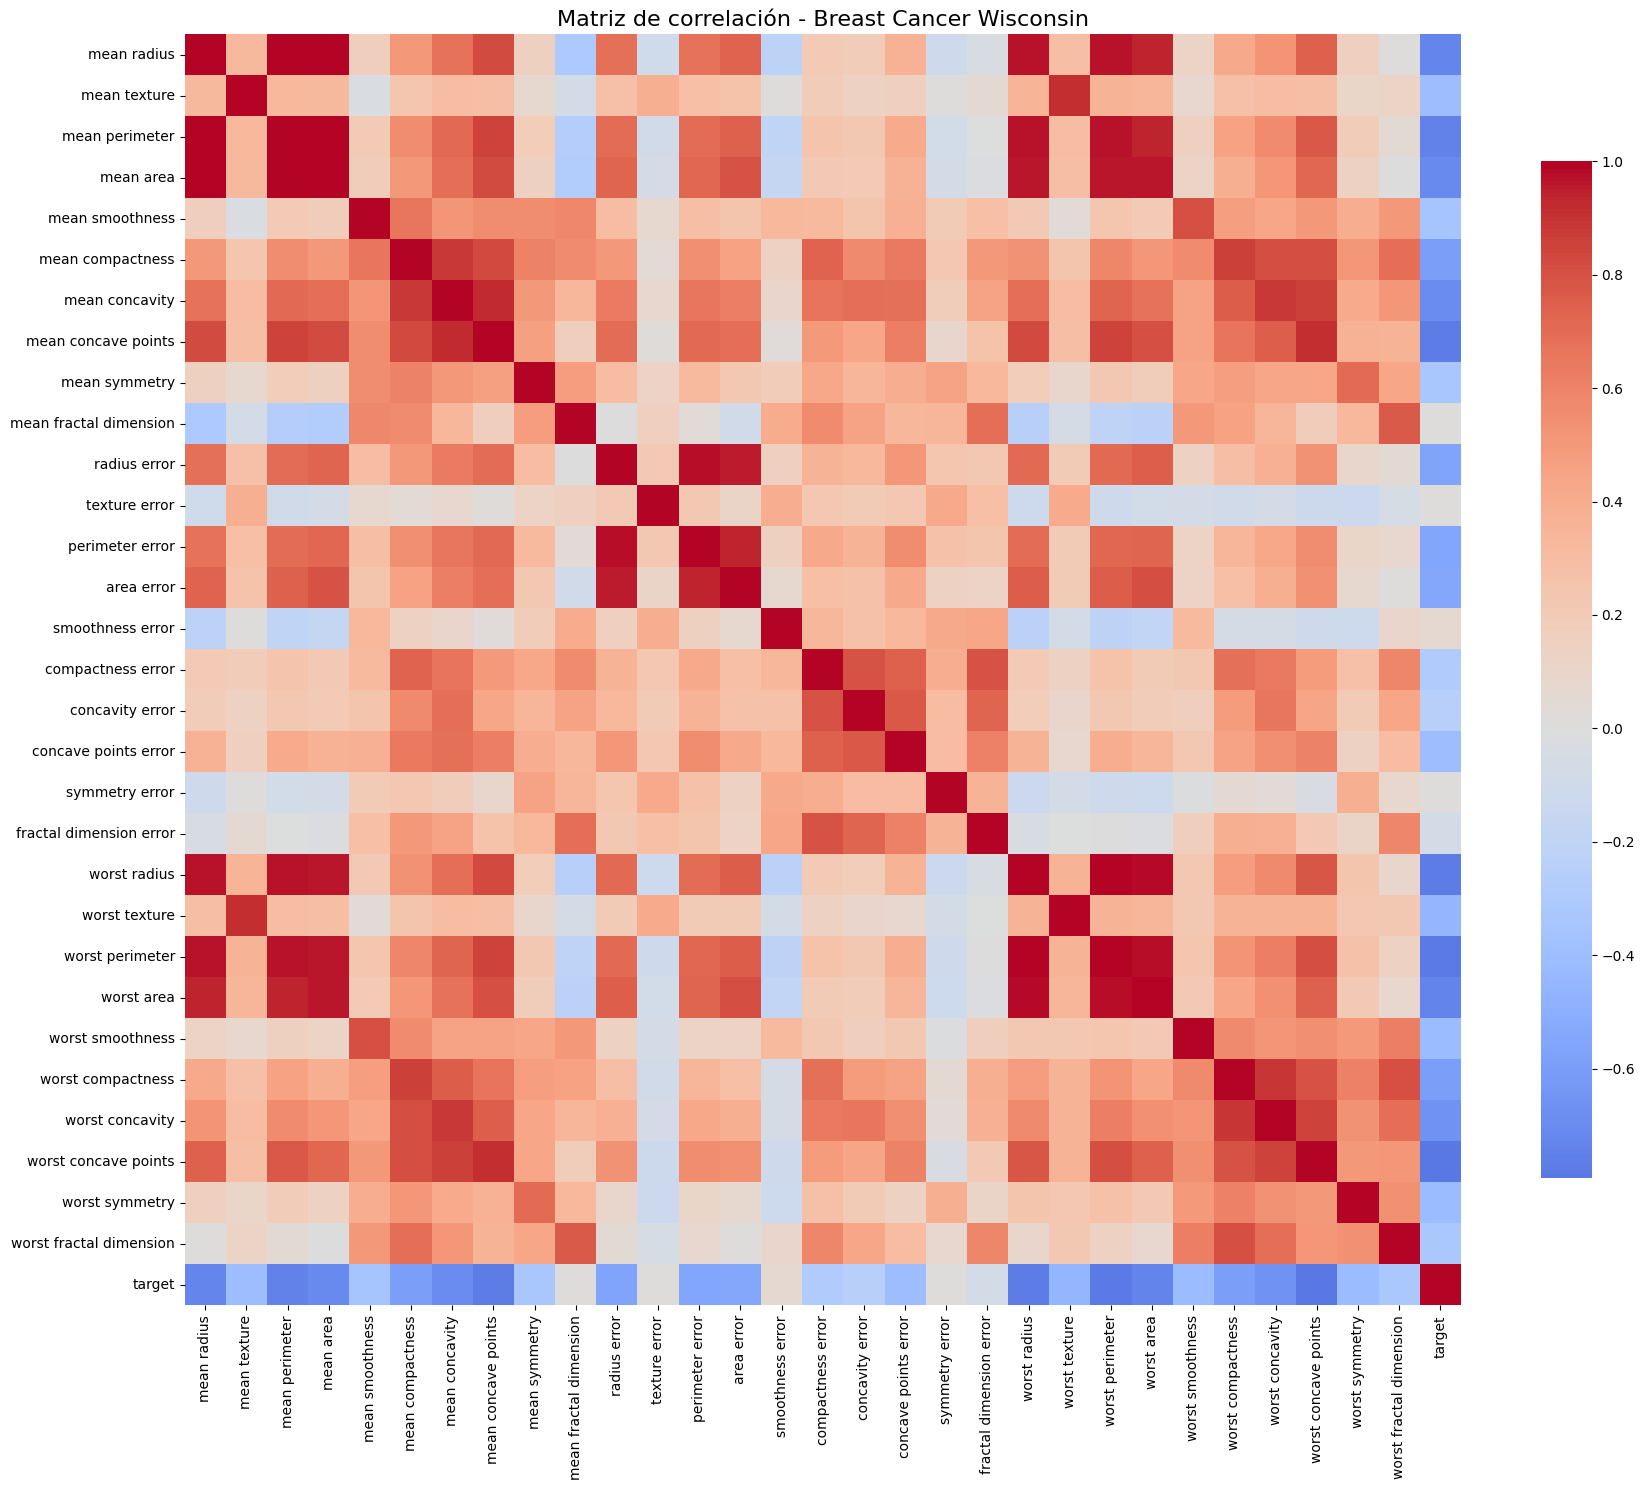

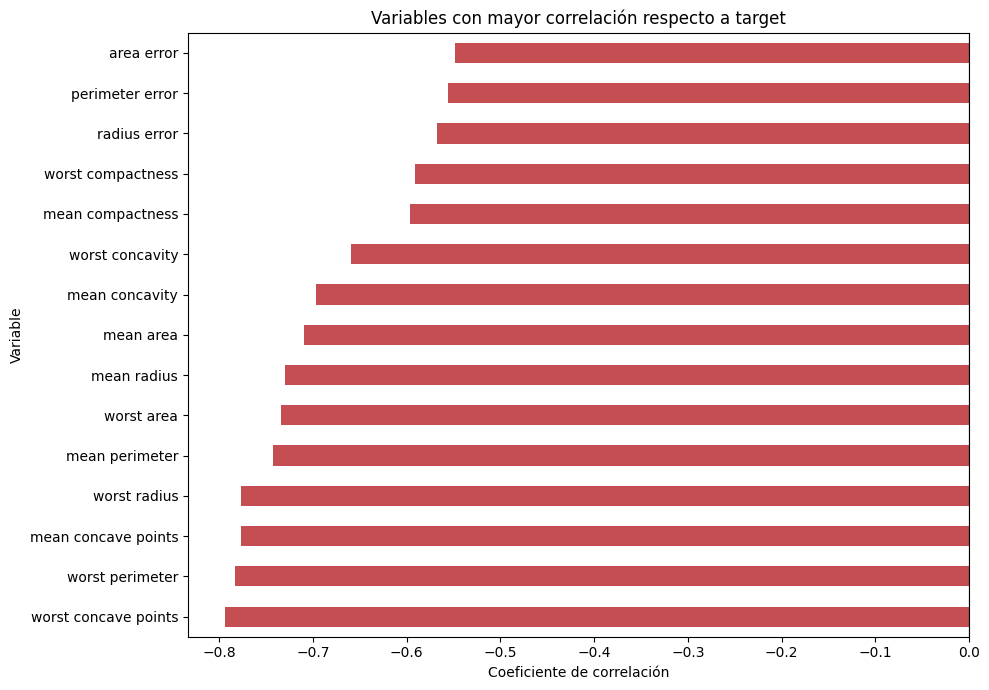

In [8]:
target_correlation = plot_correlation_matrix(df)

La matriz de correlación muestra relaciones importantes entre varias características y la variable objetivo. Debido a la codificación `0 = Maligno` y `1 = Benigno`, una correlación negativa con `target` indica que los valores altos de esa característica tienden a asociarse con casos malignos.

Para facilitar la lectura del tapete aborigen completo, se presenta también una gráfica con las variables que tienen mayor correlación absoluta con `target`.

### 3.4. Distribución de las variables predictoras

In [9]:
def plot_feature_histograms(df):
    """
    Genera histogramas para las 30 variables predictoras.
    """
    predictors = df.drop(columns=[VAL_TARGET])
    predictors.hist(bins=20, figsize=(18, 16), edgecolor="black")
    plt.suptitle("Distribución de las variables predictoras", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig("feature_histograms.png", dpi=300, bbox_inches="tight")

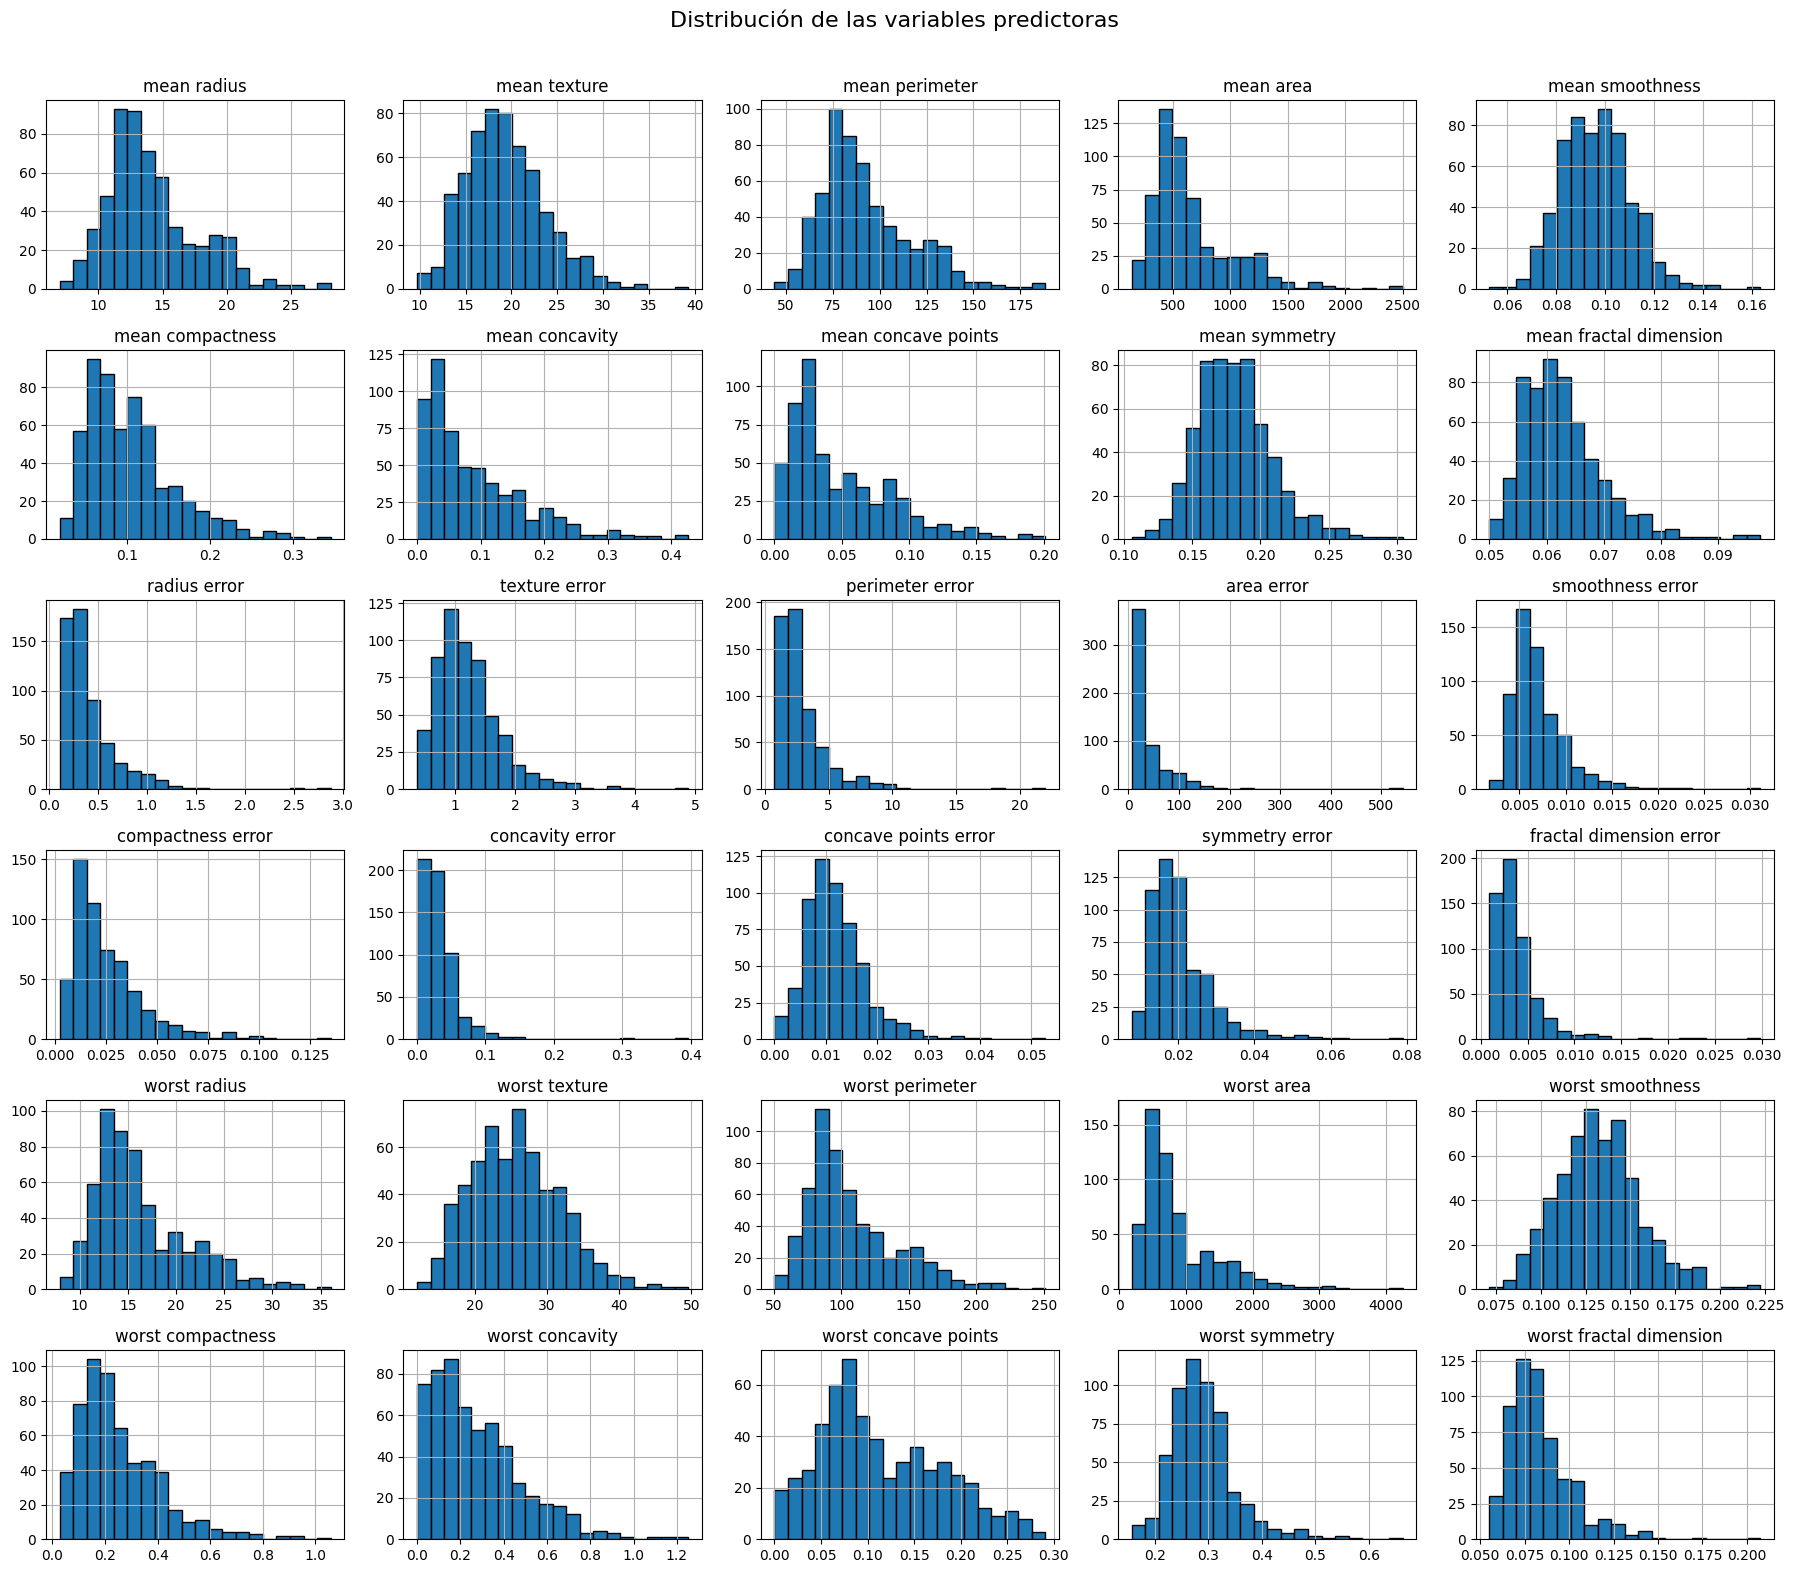

In [10]:
plot_feature_histograms(df)

Los histogramas permiten observar que varias variables presentan distribuciones asimétricas y escalas muy diferentes. Esta diferencia de escala justifica la estandarización aplicada antes de entrenar la Regresión Logística.

## 4. Preparación de los datos

Las variables predictoras se separan de la variable objetivo. El 80 % de las observaciones se utiliza para entrenamiento y el 20 % para prueba. El parámetro `stratify=y` conserva proporciones similares de casos malignos y benignos en ambos conjuntos.

In [11]:
def split_data(df):
    """
    Separa predictores y objetivo, conservando la proporción de clases.
    """

    # Separa las variables predictoras (X) de la variable objetivo (y)
    X = df.drop(columns=[VAL_TARGET])
    y = df[VAL_TARGET]

    # Divide los datos en entrenamiento y prueba
    # stratify=y mantiene proporciones similares de malignos y benignos en los conjuntos de entrenamiento y prueba
    return train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

In [12]:
X_train, X_test, y_train, y_test = split_data(df)

print("Distribución en entrenamiento:")
print(y_train.value_counts(normalize=True).sort_index())
print("\nDistribución en prueba:")
print(y_test.value_counts(normalize=True).sort_index())

Distribución en entrenamiento:
target
0    0.373626
1    0.626374
Name: proportion, dtype: float64

Distribución en prueba:
target
0    0.368421
1    0.631579
Name: proportion, dtype: float64


## 5. Funciones de evaluación

Las siguientes funciones calculan el *accuracy*, la matriz de confusión, la curva ROC y el AUC. En este análisis se considera `Benigno (1)` como clase positiva para la construcción de ROC/AUC.

In [13]:
def print_confusion_matrix_details(matrix):
    """
    Muestra la matriz de confusión y explica el significado
    de cada uno de sus valores.
    """

    malignant_correct = matrix[0, 0]
    malignant_as_benign = matrix[0, 1]
    benign_as_malignant = matrix[1, 0]
    benign_correct = matrix[1, 1]

    print("\n                        PREDICCIÓN")
    print("                    Maligno   Benigno")
    print(
        f"REAL    Maligno       {malignant_correct:3d}"
        f"       {malignant_as_benign:3d}"
    )
    print(
        f"        Benigno       {benign_as_malignant:3d}"
        f"       {benign_correct:3d}"
    )

    print(f"\nMalignos clasificados correctamente como malignos:\t{malignant_correct}")
    print(f"Benignos clasificados correctamente como benignos:\t{benign_correct}")
    print(f"Malignos clasificados incorrectamente como benignos:\t{malignant_as_benign}")
    print(f"Benignos clasificados incorrectamente como malignos:\t{benign_as_malignant}")


def evaluate_classifier(model_name, model, X_train, X_test, y_train, y_test):
    """
    Calcula accuracy, matriz de confusión, probabilidades, ROC y AUC.
    """

    # Genera predicciones sobre entrenamiento y prueba
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calcula las probabilidades estimadas para cada clase,
    # y selecciona solamente la columna 1 (Benigno) para la construcción de ROC/AUC
    y_test_probability = model.predict_proba(X_test)[:, 1]

    # Calcula la proporción de clasificaciones correctas en los conjuntos de entrenamiento y prueba
    accuracy_train = accuracy_score(y_train, y_train_pred)
    accuracy_test = accuracy_score(y_test, y_test_pred)

    # Construye la matriz de confusión, comparando el diagnóstico real con el diagnóstico que predijo el modelo
    matrix = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

    # Calcula los puntos necesarios para dibujar la curva ROC
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, y_test_probability, pos_label=1)

    # Calcula el área bajo la curva ROC usando los diagnósticos reales y las probabilidades que estimó el modelo
    auc = roc_auc_score(y_test, y_test_probability)

    print(f"\nResultados - {model_name}")
    print("-" * 50)
    print(f"Accuracy Train: {accuracy_train:.4f}")
    print(f"Accuracy Test : {accuracy_test:.4f}")
    print(f"AUC           : {auc:.4f}")
    print_confusion_matrix_details(matrix)

    return {
        "Model": model_name,
        "Accuracy Train": accuracy_train,
        "Accuracy Test": accuracy_test,
        "AUC": auc,
        "Confusion Matrix": matrix,
        "FPR": false_positive_rate,
        "TPR": true_positive_rate
    }

## 6. Regresión Logística

La Regresión Logística se incluye en un `Pipeline` junto con `StandardScaler`. El Pipeline aplica primero la estandarización y después entrena el clasificador, manteniendo ambos pasos dentro de una misma secuencia.

In [14]:
def train_logistic_regression(X_train, y_train):
    """
    Entrena un clasificador de regresión logística.
    """

    # Crea una secuencia que estandariza los predictores y entrena al clasificador de regresión logística
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ])

    # Entrena el modelo
    model.fit(X_train, y_train)

    return model

In [15]:
logistic_model = train_logistic_regression(X_train, y_train)
logistic_results = evaluate_classifier(
    "Regresión logística",
    logistic_model,
    X_train,
    X_test,
    y_train,
    y_test
)


Resultados - Regresión logística
--------------------------------------------------
Accuracy Train: 0.9890
Accuracy Test : 0.9825
AUC           : 0.9954

                        PREDICCIÓN
                    Maligno   Benigno
REAL    Maligno        41         1
        Benigno         1        71

Malignos clasificados correctamente como malignos:	41
Benignos clasificados correctamente como benignos:	71
Malignos clasificados incorrectamente como benignos:	1
Benignos clasificados incorrectamente como malignos:	1


La Regresión Logística obtuvo un *accuracy* de 0,9890 en entrenamiento y 0,9825 en prueba. Clasificó correctamente 41 de los 42 casos malignos y 71 de los 72 benignos. El AUC de 0,9954 indica una alta capacidad para diferenciar entre las dos clases.

## 7. Gaussian Naive Bayes

Gaussian Naive Bayes se entrena utilizando la misma partición de datos, lo que permite comparar ambos modelos bajo las mismas condiciones.

In [16]:
def train_naive_bayes(X_train, y_train):
    """
    Entrena un clasificador Naive Bayes con distribución gaussiana.
    """

    # Crea un clasificador Naive Bayes con distribución gaussiana
    model = GaussianNB()

    # Entrena el modelo
    model.fit(X_train, y_train)

    return model

In [17]:
naive_bayes_model = train_naive_bayes(X_train, y_train)
naive_bayes_results = evaluate_classifier(
    "Gaussian Naive Bayes",
    naive_bayes_model,
    X_train,
    X_test,
    y_train,
    y_test
)


Resultados - Gaussian Naive Bayes
--------------------------------------------------
Accuracy Train: 0.9407
Accuracy Test : 0.9386
AUC           : 0.9878

                        PREDICCIÓN
                    Maligno   Benigno
REAL    Maligno        38         4
        Benigno         3        69

Malignos clasificados correctamente como malignos:	38
Benignos clasificados correctamente como benignos:	69
Malignos clasificados incorrectamente como benignos:	4
Benignos clasificados incorrectamente como malignos:	3


Gaussian Naive Bayes obtuvo un *accuracy* de 0,9407 en entrenamiento y 0,9386 en prueba. Clasificó correctamente 38 casos malignos y 69 benignos. El AUC de 0,9878 también indica una alta capacidad para separar las clases.

## 8. Comparación de los modelos

Se comparan el *accuracy* de entrenamiento y prueba, la diferencia entre ambos y el AUC. La curva ROC permite observar el comportamiento de los dos clasificadores para distintos umbrales de decisión.

In [18]:
def plot_roc_comparison(results):
    """
    Compara las curvas ROC de ambos modelos en una sola figura.
    """
    plt.figure(figsize=(8, 6))

    for result in results:
        plt.plot(result["FPR"], result["TPR"], linewidth=2, label=f'{result["Model"]} (AUC = {result["AUC"]:.4f})')

    # La diagonal representa el comportamiento de un clasificador aleatorio.
    plt.plot([0, 1], [0, 1], "k--", label="Clasificador aleatorio")
    plt.xlabel("Tasa de falsos positivos")
    plt.ylabel("Tasa de verdaderos positivos")
    plt.title("Comparación de curvas ROC - clase positiva: Benigno")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("roc_comparison.png", dpi=300, bbox_inches="tight")

def compare_models(results):
    """
    Construye la tabla comparativa e identifica los modelos con mayor accuracy de prueba y mayor AUC.
    """
    comparison = pd.DataFrame([
        {
            "Model": result["Model"],
            "Accuracy Train": result["Accuracy Train"],
            "Accuracy Test": result["Accuracy Test"],
            "AUC": result["AUC"]
        }
        for result in results
    ])

    comparison["Accuracy Gap"] = (comparison["Accuracy Train"] - comparison["Accuracy Test"]).abs()

    print("\nCOMPARACIÓN DE MODELOS")
    print("=" * 70)
    print(comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

    # Busca la mejor precisión obtenida
    best_accuracy = comparison.loc[comparison["Accuracy Test"].idxmax(), "Model"]
    # Busca la mejor AUC obtenida
    best_auc = comparison.loc[comparison["AUC"].idxmax(), "Model"]

    print(f"\nMayor accuracy de prueba: {best_accuracy}")
    print(f"Mayor AUC: {best_auc}")

    return comparison


COMPARACIÓN DE MODELOS
               Model  Accuracy Train  Accuracy Test    AUC  Accuracy Gap
 Regresión logística          0.9890         0.9825 0.9954        0.0066
Gaussian Naive Bayes          0.9407         0.9386 0.9878        0.0021

Mayor accuracy de prueba: Regresión logística
Mayor AUC: Regresión logística


,Model,Accuracy Train,Accuracy Test,AUC,Accuracy Gap
0,Regresión logística,0.989011,0.982456,0.995370,0.006555
1,Gaussian Naive Bayes,0.940659,0.938596,0.987765,0.002063


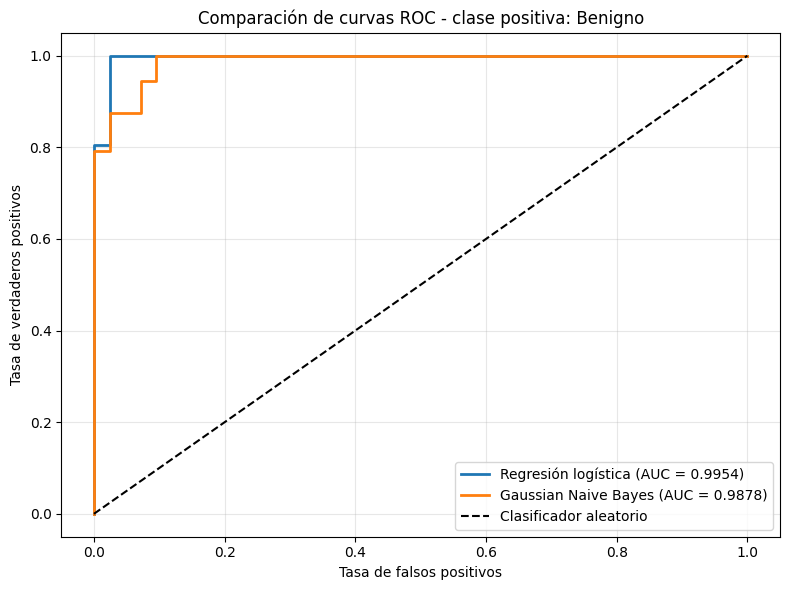

In [19]:
results = [logistic_results, naive_bayes_results]
plot_roc_comparison(results)
comparison = compare_models(results)
comparison

La Regresión Logística presentó el mejor desempeño general, con un *accuracy* de prueba de 0,9825 y un AUC de 0,9954. Gaussian Naive Bayes alcanzó un *accuracy* de 0,9386 y un AUC de 0,9878.

No se observan evidencias claras de sobreajuste: las diferencias entre el *accuracy* de entrenamiento y prueba son pequeñas en ambos modelos. Las curvas ROC se mantienen alejadas de la diagonal correspondiente a un clasificador aleatorio, aunque la Regresión Logística presenta un desempeño ligeramente superior.

## 9. Conclusiones

El análisis permitió aplicar y comparar dos modelos de clasificación binaria sobre el *Breast Cancer Wisconsin Dataset*. El análisis exploratorio identificó varias características relacionadas con el tamaño y la forma del tumor que presentan asociaciones importantes con la variable objetivo.

Ambos modelos mostraron un buen desempeño. Sin embargo, la Regresión Logística obtuvo los mejores resultados, alcanzando un *accuracy* de prueba de 0,9825 y un AUC de 0,9954. La pequeña diferencia entre entrenamiento y prueba no muestra evidencia clara de sobreajuste.

En conjunto, los resultados indican que ambos métodos permiten distinguir adecuadamente entre los casos malignos y benignos, aunque la Regresión Logística presentó la mejor capacidad predictiva para la partición de datos utilizada.